# 04 · Perfilamiento de segmentos y estrategias de marketing

**Objetivo:** describir con datos cada uno de los 4 segmentos del modelo final (K-Means, k = 4), contrastarlos con el
baseline RFM y con la marca de clientes atípicos de DBSCAN, analizar su estacionalidad y, **solo después**, darles un
nombre y proponer estrategias con acción, momento y KPI.

Los segmentos están numerados de 0 a 3 de menor a mayor gasto mediano (notebook 03). Los colores de cada segmento son
fijos y se usan igual en la app.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from segmentacion import config
from segmentacion.catalogo import CUENTAS_CLAVE, SEGMENTOS
from segmentacion.features import VARIABLES_CLUSTERING
from segmentacion.perfilamiento import (MESES_TEMPORADA, facturas_por_mes, indicadores_segmento, medias_estandarizadas,
                                        pais_principal, percentiles_medios, perfil_variables, productos_top,
                                        resumen_segmentos)
from segmentacion.visualizacion import (COLOR_BORDE_CUENTA_CLAVE, COLORES_SEGMENTO, MARCADOR_CUENTA_CLAVE, estilo,
                                        guardar_figura)

estilo()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

clientes = pd.read_parquet(config.PARQUET_SEGMENTADOS)
ventas = pd.read_parquet(config.PARQUET_LIMPIO)
preprocesador = joblib.load(config.PREPROCESADOR)
segmento = clientes["segmento"]
SEGS = sorted(segmento.unique())
print(f"{len(clientes):,} clientes · segmentos: {SEGS}")

4,324 clientes · segmentos: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## 1. Tamaño y peso en ingresos

In [2]:
resumen = resumen_segmentos(clientes, segmento)
resumen

,clientes,pct_clientes,pct_ingresos,pct_una_compra,recency_mediana,frequency_mediana,ticket_promedio_mediana,productos_distintos_mediana,monetary_mediana
segmento,,,,,,,,,
0,1040,24.05,2.72,67.50,165.00,1.00,139.34,9.00,176.92
1,1226,28.35,15.79,53.18,110.00,1.00,417.92,32.00,655.66
2,1170,27.06,11.29,12.74,23.00,3.00,228.74,44.00,700.22
3,888,20.54,70.21,0.00,11.00,8.00,381.85,123.00,"3,098.15"


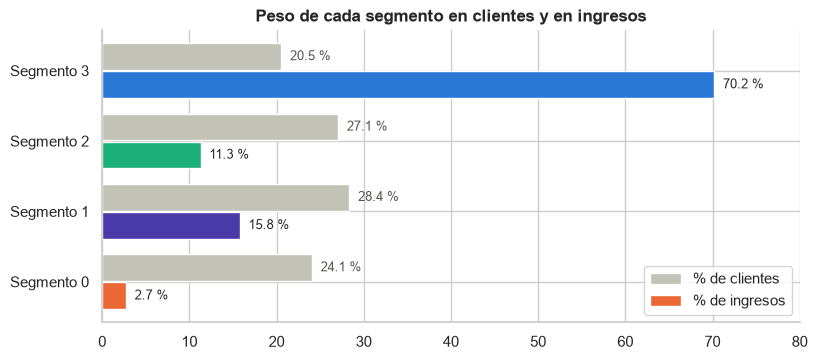

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(SEGS))
ax.barh(y + 0.2, resumen.loc[SEGS, "pct_clientes"], height=0.38, color="#c3c2b7", label="% de clientes")
ax.barh(y - 0.2, resumen.loc[SEGS, "pct_ingresos"], height=0.38, color=[COLORES_SEGMENTO[s] for s in SEGS], label="% de ingresos")
for i, s in enumerate(SEGS):
    ax.text(resumen.loc[s, "pct_ingresos"] + 1, i - 0.2, f"{resumen.loc[s, 'pct_ingresos']:.1f} %", va="center", fontsize=9)
    ax.text(resumen.loc[s, "pct_clientes"] + 1, i + 0.2, f"{resumen.loc[s, 'pct_clientes']:.1f} %", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, [f"Segmento {s}" for s in SEGS])
ax.set_xlim(0, 80)
ax.set_title("Peso de cada segmento en clientes y en ingresos")
ax.legend(loc="lower right")
guardar_figura(fig, "04_peso_segmentos")
plt.show()

In [4]:
VARIABLES_PERFIL = ["recency", "frequency", "monetary", "ticket_promedio", "productos_distintos", "antiguedad",
                    "dias_entre_compras", "unidades_por_factura", "tasa_devoluciones"]
perfil = perfil_variables(clientes, segmento, VARIABLES_PERFIL)
perfil["mediana"].T

segmento,0,1,2,3
recency,165.00,110.00,23.00,11.00
frequency,1.00,1.00,3.00,8.00
monetary,176.92,655.66,700.22,"3,098.15"
ticket_promedio,139.34,417.92,228.74,381.85
productos_distintos,9.00,32.00,44.00,123.00
antiguedad,219.50,222.00,212.00,335.00
dias_entre_compras,62.57,73.78,69.03,35.50
unidades_por_factura,73.00,250.17,136.29,232.15
tasa_devoluciones,0.00,0.00,0.00,0.00


In [5]:
perfil['media'].T

segmento,0,1,2,3
recency,169.15,141.94,30.68,20.06
frequency,1.51,1.82,3.29,11.96
monetary,217.24,"1,070.28",802.09,"6,571.75"
ticket_promedio,150.36,587.91,251.74,491.83
productos_distintos,11.85,43.37,51.08,157.17
antiguedad,206.96,206.44,195.94,305.12
dias_entre_compras,84.62,90.94,89.05,39.96
unidades_por_factura,93.92,356.62,162.31,290.89
tasa_devoluciones,0.01,0.01,0.01,0.01


**Hallazgos — tamaño y valor**

- **Segmento 3:** es el **20,5 % de los clientes y genera el 70,2 % de los ingresos**. Su cliente mediano compró hace 11
  días, lleva 8 facturas, 123 productos distintos y 3.098 £ de gasto. Es el más antiguo (335 días de mediana frente a
  212–222 en el resto) y el que repite más rápido (35,5 días entre compras frente a 62–74).
- **Segmento 1:** 28,4 % de los clientes y 15,8 % de los ingresos. Tiene el **ticket más alto** (417,92 £ de mediana) y
  las facturas con más unidades (250), pero una sola factura de mediana y 110 días sin comprar.
- **Segmento 2:** 27,1 % de los clientes y 11,3 % de los ingresos. Clientes recientes (23 días) con 3 facturas y ticket
  medio (228,74 £).
- **Segmento 0:** 24,1 % de los clientes y solo el 2,7 % de los ingresos. Una factura, ticket de 139,34 £, 9 productos y
  73 unidades por factura (todo lo más bajo).
- Las medias superan a las medianas en todos los segmentos (por ejemplo, en el segmento 1 el gasto medio es de
  1.070,28 £ frente a una mediana de 655,66 £): dentro de cada segmento sigue habiendo clientes muy grandes. Por eso se
  describe con medianas.

## 2. Snake plot y radar

- **Snake plot:** media de cada variable de clustering **estandarizada** (0 = cliente medio, ±1 = una desviación típica)
  por segmento. Es la "firma" del segmento en el espacio donde K-Means lo encontró.
- **Radar:** percentil medio de los clientes del segmento en cada variable (0–100, misma escala para todas). La recencia
  se invierte para que "más alto = mejor" en todos los ejes.

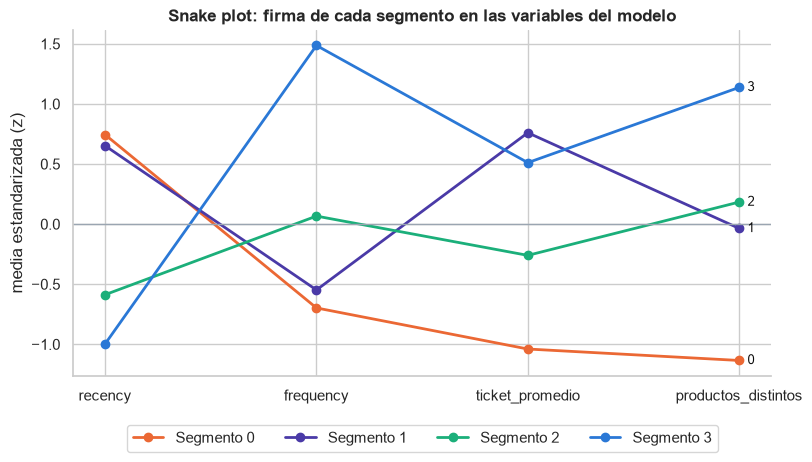

,recency,frequency,ticket_promedio,productos_distintos
segmento,,,,
0,0.74,-0.70,-1.04,-1.13
1,0.65,-0.55,0.76,-0.04
2,-0.59,0.07,-0.26,0.18
3,-1.00,1.49,0.51,1.14


In [6]:
Z = preprocesador.transform(clientes[VARIABLES_CLUSTERING])
snake = medias_estandarizadas(Z, segmento.to_numpy(), VARIABLES_CLUSTERING)
fig, ax = plt.subplots(figsize=(9, 4.5))
for s in SEGS:
    ax.plot(VARIABLES_CLUSTERING, snake.loc[s], marker="o", lw=2, color=COLORES_SEGMENTO[s], label=f"Segmento {s}")
    ax.annotate(f"{s}", (len(VARIABLES_CLUSTERING) - 1, snake.loc[s].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color="#0b0b0b", fontsize=9, va="center")
ax.axhline(0, color="#9AA5B1", lw=1)
ax.set_ylabel("media estandarizada (z)")
ax.set_title("Snake plot: firma de cada segmento en las variables del modelo")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
guardar_figura(fig, "04_snake_plot")
plt.show()
snake

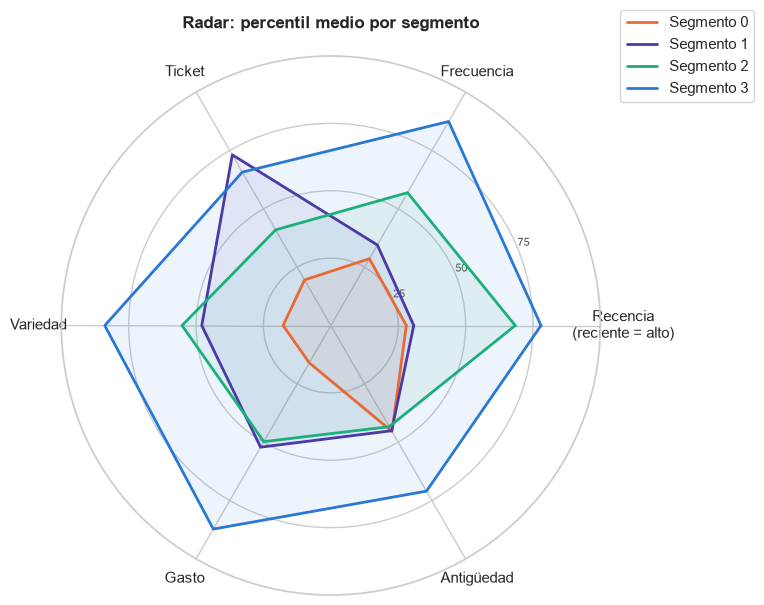

,recency,frequency,ticket_promedio,productos_distintos,monetary,antiguedad
segmento,,,,,,
0,28.00,28.61,19.53,17.71,16.00,45.41
1,30.77,34.50,73.13,47.89,52.13,45.10
2,68.42,56.91,40.97,55.22,49.77,43.35
3,77.99,87.42,65.71,83.89,87.23,70.97


In [7]:
VARIABLES_RADAR = ["recency", "frequency", "ticket_promedio", "productos_distintos", "monetary", "antiguedad"]
ETIQUETAS_RADAR = ["Recencia\n(reciente = alto)", "Frecuencia", "Ticket", "Variedad", "Gasto", "Antigüedad"]
radar = percentiles_medios(clientes, segmento.to_numpy(), VARIABLES_RADAR, invertir=("recency",))
angulos = np.linspace(0, 2 * np.pi, len(VARIABLES_RADAR), endpoint=False).tolist()
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})
for s in SEGS:
    valores = radar.loc[s].tolist()
    ax.plot(angulos + angulos[:1], valores + valores[:1], lw=2, color=COLORES_SEGMENTO[s], label=f"Segmento {s}")
    ax.fill(angulos + angulos[:1], valores + valores[:1], color=COLORES_SEGMENTO[s], alpha=0.08)
ax.set_xticks(angulos, ETIQUETAS_RADAR)
ax.set_ylim(0, 100)
ax.set_yticks([25, 50, 75], ["25", "50", "75"], color="#52514e", fontsize=8)
ax.set_title("Radar: percentil medio por segmento", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
guardar_figura(fig, "04_radar")
plt.show()
radar

**Hallazgos — snake plot y radar**

- **Segmento 0:** está por debajo de la media en todo. Lo que más lo distingue es el **ticket (−1,04 desviaciones
  típicas) y la variedad (−1,13)**, más que la recency (+0,74).
- **Segmento 1:** tiene casi la misma recency que el 0 (+0,65) y también poca frecuencia (−0,55), pero el **ticket más
  alto de todos (+0,76)**. En el radar su percentil de ticket (73,1) supera incluso al del segmento 3 (65,7). La
  diferencia entre los segmentos 0 y 1 es el tamaño del pedido, no la actividad.
- **Segmento 2:** destaca solo por la recencia (−0,59, es decir, compraron hace poco); en lo demás está cerca de la media.
  En el radar ocupa el centro en todas las variables menos en recencia (percentil 68,4).
- **Segmento 3:** está muy por encima en frecuencia (+1,49) y variedad (+1,14) y es el más reciente (−1,00). En el radar
  domina en todos los ejes salvo el ticket, y es el único con antigüedad alta (percentil 71,0 frente a 43–45 del resto).

## 3. Coherencia con el baseline RFM por quintiles

segmento RFM,Campeones,Leales,Potenciales leales,Nuevos,Prometedores,Necesitan atención,A punto de dormir,En riesgo,No se pueden perder,Hibernando,total
segmento,,,,,,,,,,,
0,4,17,61,5,38,34,124,199,4,554,1040
1,1,43,52,1,21,73,180,319,13,523,1226
2,147,393,352,35,34,79,41,68,20,1,1170
3,478,363,17,0,0,1,0,4,25,0,888


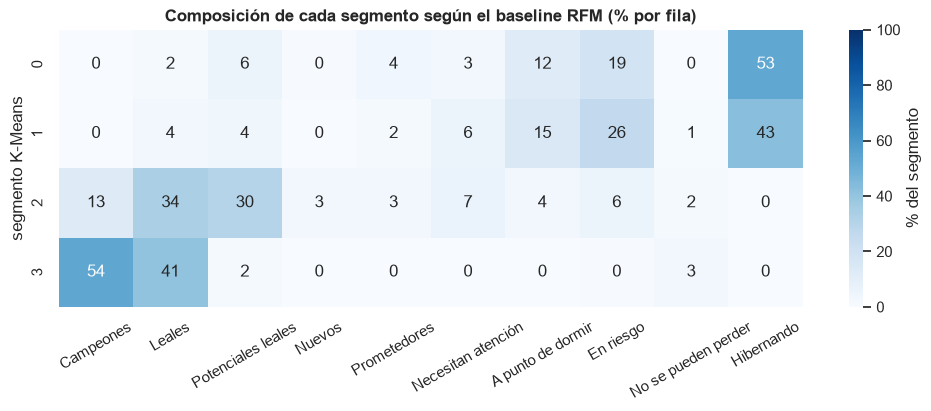

In [8]:
contingencia = pd.crosstab(segmento.rename("segmento"), clientes["segmento_rfm"].rename("segmento RFM"))
orden_rfm = ["Campeones", "Leales", "Potenciales leales", "Nuevos", "Prometedores", "Necesitan atención",
             "A punto de dormir", "En riesgo", "No se pueden perder", "Hibernando"]
contingencia = contingencia[orden_rfm]
display(contingencia.assign(total=contingencia.sum(axis=1)))
por_fila = contingencia.div(contingencia.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(por_fila, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% del segmento"}, ax=ax)
ax.set_title("Composición de cada segmento según el baseline RFM (% por fila)")
ax.set_ylabel("segmento K-Means")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
guardar_figura(fig, "04_contingencia_rfm")
plt.show()

In [9]:
grupos_rfm = {"Activos de valor (Campeones + Leales)": ["Campeones", "Leales"],
              "En desarrollo (Potenciales leales + Nuevos + Prometedores)": ["Potenciales leales", "Nuevos", "Prometedores"],
              "En riesgo (Necesitan atención + A punto de dormir + En riesgo + No se pueden perder)":
                  ["Necesitan atención", "A punto de dormir", "En riesgo", "No se pueden perder"],
              "Hibernando": ["Hibernando"]}
pd.DataFrame({g: por_fila[cols].sum(axis=1) for g, cols in grupos_rfm.items()}).round(1)

,Activos de valor (Campeones + Leales),En desarrollo (Potenciales leales + Nuevos + Prometedores),En riesgo (Necesitan atención + A punto de dormir + En riesgo + No se pueden perder),Hibernando
segmento,,,,
0,2.00,10.00,34.70,53.30
1,3.60,6.00,47.70,42.70
2,46.20,36.00,17.80,0.10
3,94.70,1.90,3.40,0.00


**Hallazgos — coherencia con el baseline RFM**

- **Segmento 3:** el **94,7 % son "Campeones" o "Leales"** según RFM (478 y 363 clientes). Ambas segmentaciones coinciden
  en quiénes son los mejores clientes.
- **Segmento 2:** mezcla clientes activos de valor (46,2 %: "Leales" 393 y "Campeones" 147) con clientes en desarrollo
  (36,0 %, sobre todo "Potenciales leales"). Encaja con un segmento que está creciendo, y apenas tiene "Hibernando" (1
  cliente).
- **Segmentos 0 y 1:** RFM los ve casi igual: los dos son mayoritariamente "Hibernando" (53,3 % y 42,7 %) o "en riesgo"
  (34,7 % y 47,7 %). **K-Means los separa por el ticket**, algo que el mapa RFM (que segmenta solo con R y F) no ve.
  Esa separación importa: el segmento 1 aporta el 15,8 % de los ingresos y el 0 solo el 2,7 %, así que merecen
  inversiones de reactivación muy distintas. Es el principal valor añadido del clustering frente al baseline.

## 4. Clientes atípicos (DBSCAN) por segmento

DBSCAN (notebook 03) marcó como ruido a los clientes alejados de la masa principal. ¿Se concentran en algún segmento?

In [10]:
atipico = clientes["dbscan"].eq(-1)
tabla_atip = pd.DataFrame({
    "clientes": segmento.value_counts().sort_index(),
    "atipicos": atipico.groupby(segmento).sum(),
})
tabla_atip["pct_del_segmento"] = 100 * tabla_atip["atipicos"] / tabla_atip["clientes"]
tabla_atip["pct_de_los_atipicos"] = 100 * tabla_atip["atipicos"] / atipico.sum()
tabla_atip["pct_de_los_clientes"] = 100 * tabla_atip["clientes"] / len(clientes)
tabla_atip["ingresos_atipicos"] = clientes.loc[atipico].groupby("segmento")["monetary"].sum()
tabla_atip["pct_ingresos_atipicos"] = 100 * tabla_atip["ingresos_atipicos"] / clientes.loc[atipico, "monetary"].sum()
tabla_atip["monetary_mediano_atipicos"] = clientes.loc[atipico].groupby("segmento")["monetary"].median()
tabla_atip

,clientes,atipicos,pct_del_segmento,pct_de_los_atipicos,pct_de_los_clientes,ingresos_atipicos,pct_ingresos_atipicos,monetary_mediano_atipicos
segmento,,,,,,,,
0,1040,25,2.40,15.34,24.05,"5,989.07",0.20,84.65
1,1226,45,3.67,27.61,28.35,"244,492.57",8.19,"4,163.98"
2,1170,21,1.79,12.88,27.06,"32,920.24",1.10,"1,133.25"
3,888,72,8.11,44.17,20.54,"2,700,670.52",90.50,"19,960.08"


**Criterio de cuenta clave.** DBSCAN marca como atípico a quien se aleja de la masa de clientes **en cualquier
dirección**. La estrategia de cuentas clave (gestor dedicado, condiciones negociadas) se justifica por **volumen**, así que
se exige además que el cliente gaste al menos la mediana del resto de VIP. Los atípicos VIP que no lo cumplen son
compradores muy frecuentes de pedidos pequeños y se quedan en el programa VIP general.

In [11]:
vip_no_atipico = segmento.eq(3) & ~atipico
umbral_gasto = clientes.loc[vip_no_atipico, "monetary"].median()
cuenta_clave = atipico & segmento.eq(3) & (clientes["monetary"] >= umbral_gasto)
excluidos = atipico & segmento.eq(3) & ~cuenta_clave
print(f"Umbral de gasto (mediana de los VIP no atípicos): {umbral_gasto:,.2f} £")
print(f"Atípicos VIP: {(atipico & segmento.eq(3)).sum()} · cuentas clave: {cuenta_clave.sum()} · excluidos por gasto: {excluidos.sum()} "
      f"({100 * clientes.loc[excluidos, 'monetary'].sum() / clientes.loc[atipico & segmento.eq(3), 'monetary'].sum():.1f} % de los ingresos de los atípicos VIP)")
display(clientes.loc[excluidos, VARIABLES_CLUSTERING + ["monetary"]])

Umbral de gasto (mediana de los VIP no atípicos): 2,936.20 £
Atípicos VIP: 72 · cuentas clave: 66 · excluidos por gasto: 6 (0.5 % de los ingresos de los atípicos VIP)


,recency,frequency,ticket_promedio,productos_distintos,monetary
CustomerID,,,,,
13695,32,15,166.94,46,"2,504.13"
14397,3,19,137.52,18,"2,612.96"
14560,8,21,104.01,39,"2,184.13"
16928,81,17,165.03,68,"2,805.50"
17961,22,39,33.24,211,"1,296.44"
18241,10,17,121.06,59,"2,058.09"


In [12]:
comparacion = clientes.assign(grupo=np.select([cuenta_clave, segmento.eq(3)], ["Cuenta clave", "VIP resto"], "otros"))
comparacion = comparacion[comparacion["grupo"] != "otros"]
print(f"Cuentas clave: {cuenta_clave.sum()} clientes ({100 * cuenta_clave.mean():.1f} % de la base) · "
      f"ingresos: {100 * clientes.loc[cuenta_clave, 'monetary'].sum() / clientes['monetary'].sum():.1f} % del total · "
      f"gasto mínimo: {clientes.loc[cuenta_clave, 'monetary'].min():,.2f} £")
comparacion.groupby("grupo")[["recency", "frequency", "ticket_promedio", "productos_distintos", "monetary", "tasa_devoluciones"]].median()

Cuentas clave: 66 clientes (1.5 % de la base) · ingresos: 32.3 % del total · gasto mínimo: 3,152.69 £


,recency,frequency,ticket_promedio,productos_distintos,monetary,tasa_devoluciones
grupo,,,,,,
Cuenta clave,8.00,26.00,"1,078.19",85.00,"23,278.22",0.00
VIP resto,12.00,8.00,368.28,125.00,"2,916.18",0.00


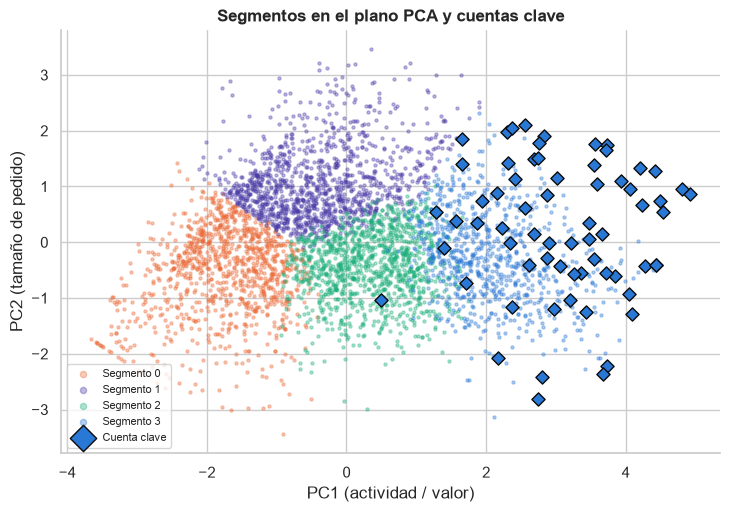

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
coords = clientes[["pc1", "pc2"]].to_numpy()
for s in SEGS:
    m = segmento.eq(s).to_numpy() & ~cuenta_clave.to_numpy()
    ax.scatter(coords[m, 0], coords[m, 1], s=5, alpha=0.35, color=COLORES_SEGMENTO[s], label=f"Segmento {s}")
ax.scatter(coords[cuenta_clave, 0], coords[cuenta_clave, 1], s=45, marker=MARCADOR_CUENTA_CLAVE, facecolor=COLORES_SEGMENTO[3],
           edgecolor=COLOR_BORDE_CUENTA_CLAVE, linewidths=1, label="Cuenta clave")
ax.set_xlabel("PC1 (actividad / valor)")
ax.set_ylabel("PC2 (tamaño de pedido)")
ax.set_title("Segmentos en el plano PCA y cuentas clave")
ax.legend(markerscale=2, fontsize=8, loc="lower left")
guardar_figura(fig, "04_cuentas_clave_pca")
plt.show()

**Hallazgos — atípicos y cuentas clave**

- **Los atípicos de DBSCAN se concentran en el segmento 3:** tiene el 20,5 % de los clientes pero el **44,2 % de los
  atípicos** (72 de 163, más del doble de lo esperado), y esos 72 generan el **90,5 % de los ingresos de todos los
  atípicos**.
- **Los atípicos de los otros segmentos son de otra naturaleza:**
  - Segmento 1 (45): grandes pedidos puntuales (mediana 4.163,98 £).
  - Segmento 0 (25): atípicos por abajo (mediana 84,65 £).
  - Segmento 2 (21): mediana 1.133,25 £.
- **Criterio de cuenta clave:** VIP + atípico + gasto ≥ mediana de los VIP no atípicos (2.936,20 £). Se excluyen 6 VIP
  atípicos que lo son por una **frecuencia extrema con pedidos pequeños** (15–39 facturas y ticket de 33–167 £); solo
  suponen el 0,5 % de los ingresos de los atípicos VIP.
- **Resultado: 66 cuentas clave, el 1,5 % de los clientes, que generan el 32,3 % de todos los ingresos.** Frente al resto
  de VIP compran el triple de veces (26 facturas frente a 8), con un ticket casi tres veces mayor (1.078,19 £ frente a
  368,28 £) pero con **menos variedad** (85 productos frente a 125). Son compradores de gran volumen y surtido más
  concentrado: perfiles de mayorista o revendedor.
- En el plano PCA ocupan el **extremo derecho** del segmento VIP (PC1 alto: máxima actividad y valor), repartidas a lo
  largo de PC2: unas destacan por pedidos muy grandes y otras por comprar con muchísima frecuencia.

## 5. País y productos

In [14]:
pais_principal(clientes, segmento.to_numpy())

,pais_principal,pct_pais_principal,segundo_pais,pct_segundo_pais,paises_distintos
0,United Kingdom,93.56,France,1.63,22
1,United Kingdom,86.05,Germany,2.53,35
2,United Kingdom,92.74,France,2.05,21
3,United Kingdom,89.64,Germany,3.15,20


In [15]:
top_importe = productos_top(ventas, segmento, n=5, criterio="importe")
top_importe.pivot(index="posicion", columns="segmento", values="descripcion")

segmento,0,1,2,3
posicion,,,,
1,WHITE HANGING HEART T-LIGHT HOLDER,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER
2,REGENCY CAKESTAND 3 TIER,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER
3,JUMBO BAG RED RETROSPOT,PARTY BUNTING,ASSORTED COLOUR BIRD ORNAMENT,JUMBO BAG RED RETROSPOT
4,CHILLI LIGHTS,JUMBO BAG RED RETROSPOT,PARTY BUNTING,PARTY BUNTING
5,DOORMAT UNION FLAG,CHILLI LIGHTS,PAPER CHAIN KIT 50'S CHRISTMAS,ASSORTED COLOUR BIRD ORNAMENT


In [16]:
top_penetracion = productos_top(ventas, segmento, n=5, criterio="penetracion")
tabla_pen = top_penetracion.assign(texto=lambda d: d["descripcion"] + " (" + d["valor"].round(1).astype(str) + " %)")
tabla_pen.pivot(index="posicion", columns="segmento", values="texto")

segmento,0,1,2,3
posicion,,,,
1,WHITE HANGING HEART T-LIGHT HOLDER (10.0 %),REGENCY CAKESTAND 3 TIER (20.7 %),WHITE HANGING HEART T-LIGHT HOLDER (18.5 %),REGENCY CAKESTAND 3 TIER (39.4 %)
2,REGENCY CAKESTAND 3 TIER (7.1 %),WHITE HANGING HEART T-LIGHT HOLDER (17.5 %),REX CASH+CARRY JUMBO SHOPPER (17.4 %),WHITE HANGING HEART T-LIGHT HOLDER (35.9 %)
3,PARTY BUNTING (6.1 %),SET OF 3 CAKE TINS PANTRY DESIGN (15.4 %),REGENCY CAKESTAND 3 TIER (16.7 %),JUMBO BAG RED RETROSPOT (35.6 %)
4,REX CASH+CARRY JUMBO SHOPPER (6.0 %),PARTY BUNTING (15.3 %),PAPER CHAIN KIT 50'S CHRISTMAS (15.7 %),PACK OF 72 RETROSPOT CAKE CASES (35.1 %)
5,ANTIQUE SILVER T-LIGHT GLASS (5.1 %),ASSORTED COLOUR BIRD ORNAMENT (14.9 %),ASSORTED COLOUR BIRD ORNAMENT (14.9 %),LUNCH BAG RED RETROSPOT (34.0 %)


In [17]:
codigos_top = {s: set(top_importe.loc[top_importe["segmento"] == s, "StockCode"]) for s in SEGS}
comunes = set.intersection(*codigos_top.values())
print(f"Productos que están en el top-5 por importe de los {len(SEGS)} segmentos: {len(comunes)} → "
      f"{sorted(top_importe.loc[top_importe['StockCode'].isin(comunes), 'descripcion'].unique())}")

Productos que están en el top-5 por importe de los 4 segmentos: 2 → ['REGENCY CAKESTAND 3 TIER', 'WHITE HANGING HEART T-LIGHT HOLDER']


**Hallazgos — país y productos**

- **Reino Unido** es el país principal en todos los segmentos (del 86,1 % al 93,6 %). El segundo país pesa muy poco:
  Francia en los segmentos 0 y 2, y Alemania en el 1 y el 3 (1,6–3,2 %). El segmento 1 es el más internacional, con 35
  países distintos y el menor peso de Reino Unido.
- **Los productos más facturados son prácticamente los mismos en todos los segmentos:** "REGENCY CAKESTAND 3 TIER" y
  "WHITE HANGING HEART T-LIGHT HOLDER" están en el top-5 de los cuatro. Los segmentos no se diferencian por *qué*
  compran sino por *cuánto, cuántas veces y cuánta variedad*. Las estrategias se apoyan en el comportamiento, no en el
  surtido.
- **Penetración:** en el segmento 3 los productos estrella los compra más de un tercio de los clientes (34–39 %), frente
  a un 5–10 % en el segmento 0. En el segmento 2 aparece entre los más comprados un artículo navideño (PAPER CHAIN KIT
  50'S CHRISTMAS, 15,7 %), coherente con su entrada en la campaña de Navidad (sección 6).

## 6. Estacionalidad

¿En qué meses compra cada segmento? Se mira el reparto de sus facturas por mes y, aparte, el de los clientes de **una sola
factura** (¿cuándo hicieron su única compra?). Temporada de Navidad = **septiembre–noviembre** (`MESES_TEMPORADA`), los
meses de mayor facturación del año según el notebook 01. Diciembre de 2011 está incompleto (hasta el día 9).

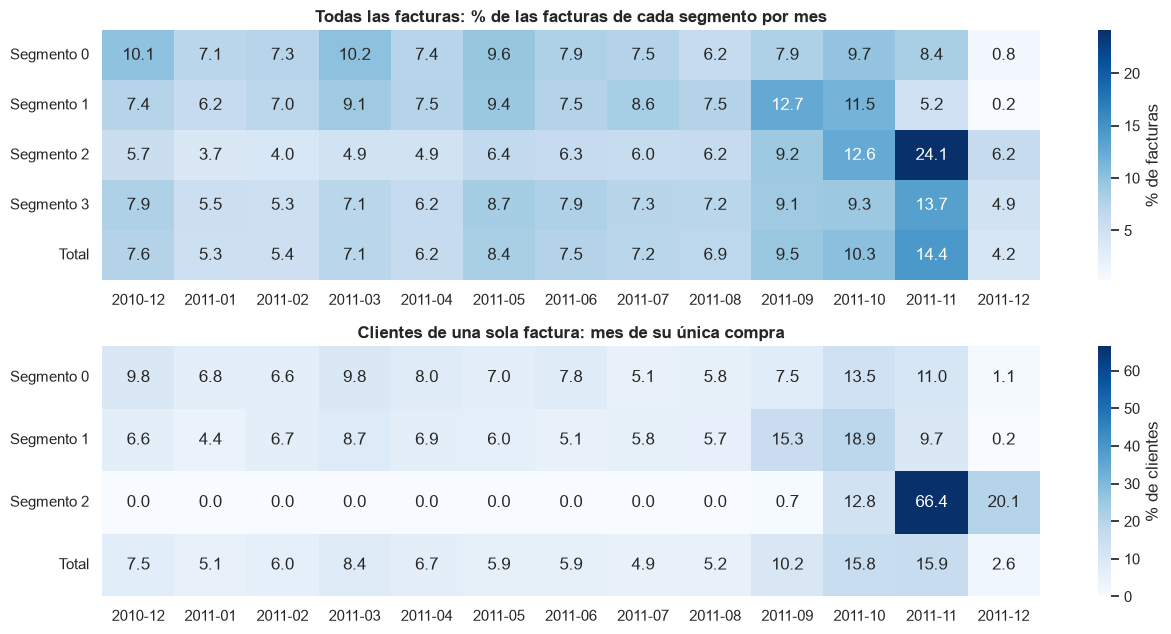

Clientes de una sola factura por segmento: {0: 702, 1: 652, 2: 149}


In [18]:
por_mes = facturas_por_mes(ventas, segmento)
etiquetas_filas = {s: f"Segmento {s}" for s in SEGS} | {"Total": "Total"}
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
sns.heatmap(por_mes.rename(index=etiquetas_filas), annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar_kws={"label": "% de facturas"})
axes[0].set_title("Todas las facturas: % de las facturas de cada segmento por mes")
una_compra = clientes.index[clientes["frequency"] == 1]
por_mes_una = facturas_por_mes(ventas, segmento, clientes_incluidos=una_compra)
sns.heatmap(por_mes_una.rename(index=etiquetas_filas), annot=True, fmt=".1f", cmap="Blues", ax=axes[1], cbar_kws={"label": "% de clientes"})
axes[1].set_title("Clientes de una sola factura: mes de su única compra")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.tight_layout()
guardar_figura(fig, "04_estacionalidad")
plt.show()
print("Clientes de una sola factura por segmento:", clientes.loc[una_compra, "segmento"].value_counts().sort_index().to_dict())

In [19]:
indicadores = indicadores_segmento(clientes, ventas, segmento)
meses = [c for c in por_mes.columns if c.month in MESES_TEMPORADA]
estacional = pd.DataFrame(index=por_mes.index)
estacional["% facturas en sep–nov"] = por_mes[meses].sum(axis=1)
estacional["% de los de 1 factura que compró en sep–nov"] = por_mes_una[meses].sum(axis=1).reindex(estacional.index)
oct_dic = [c for c in por_mes_una.columns if c.year == 2011 and c.month >= 10]
estacional["% de los de 1 factura que compró en oct–dic"] = por_mes_una[oct_dic].sum(axis=1).reindex(estacional.index)
estacional["% captados desde oct-2011"] = indicadores["pct_captados_temporada"].reindex(estacional.index)
estacional

,% facturas en sep–nov,% de los de 1 factura que compró en sep–nov,% de los de 1 factura que compró en oct–dic,% captados desde oct-2011
segmento,,,,
0,26.02,32.05,25.64,19.13
1,29.42,43.87,28.68,16.15
2,45.86,79.87,99.33,25.47
3,32.13,NaN,NaN,2.59
Total,34.16,41.92,34.26,NaN


**Hallazgos — estacionalidad**

- **En el conjunto de facturas,** el segmento 2 es el más estacional: el 45,9 % de sus facturas son de
  septiembre–noviembre (y el 24,1 % solo de noviembre), frente al 34,2 % del total. El segmento 3 sigue el patrón general
  (32,1 %; noviembre 13,7 % frente a 14,4 %), y los segmentos 0 y 1 están por debajo (26,0 % y 29,4 %).
- **Clientes de una sola factura** (702 en el segmento 0, 652 en el 1 y 149 en el 2):
  - **Segmento 1:** el **43,9 %** hizo su única compra en septiembre–noviembre, el 34,2 % en septiembre–octubre
    (frente al 26,0 % del total de clientes de una sola factura en esos dos meses). Es un patrón de
    **aprovisionamiento para Navidad**: pedidos grandes antes de la temporada y sin repetición.
  - **Segmento 2:** el **99,3 %** compró en octubre–diciembre (66,4 % solo en noviembre). Son **clientes captados en la
    campaña de Navidad**: el 25,5 % del segmento hizo su primera compra desde octubre de 2011.
  - **Segmento 0:** reparto más plano (32,1 % en septiembre–noviembre), sin una concentración clara.
- **Salvedad:** el mes de compra no es independiente de la recency, que es una de las variables del modelo. El segmento 2
  es reciente por construcción, así que su concentración en octubre–diciembre es en parte consecuencia de cómo se formó.
  La del segmento 1 sí aporta información (su recency mediana es de 110 días, pero sus compras únicas se acumulan justo
  antes de la temporada). Con un solo año de datos no se puede confirmar que estos clientes repitan cada Navidad: las
  estrategias lo tratan como hipótesis a validar con su KPI.
- **Reflejo en las estrategias:** pre-temporada en agosto–septiembre para el segmento 1, retención en enero–febrero de
  los captados en Navidad del segmento 2, programa VIP y planificación con las cuentas clave en julio–agosto, y
  reactivación del segmento 0 en octubre.